In [74]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, random_split, ConcatDataset

import torchvision
from torchvision.transforms import v2


In [75]:
torch.manual_seed(42)

In [76]:
transforms = v2.Compose(
    [
        v2.ToImage(),
        v2.RGB(),
        v2.ToDtype(torch.uint8, scale=True),
        v2.Resize(size=(256), antialias=True),
        v2.CenterCrop(224),
        v2.ToDtype(torch.float32, scale = True),
        v2.Normalize((0.5363, 0.5081, 0.4785), (0.3014, 0.2941, 0.3063))
    ]
)

In [77]:
caltech101_data = torchvision.datasets.Caltech101(root='caltech101', download = True, transform=transforms)

In [78]:
# train and tset split

total_size = len(caltech101_data)
train_size = int(0.8 * total_size)
test_size = total_size - train_size

train_dataset, test_dataset = random_split(
    caltech101_data, [train_size, test_size]
)

print(len(caltech101_data)==len(train_dataset)+len(test_dataset))
print(len(train_dataset))
print(len(test_dataset))

True
6941
1736


In [79]:
# calculating mean and std for normalization parameter

# stack all train images together into a tensor of shape
# (len(train_dataset), 3, 32, 32)
x = torch.stack([sample[0] for sample in ConcatDataset([train_dataset])])

# get the mean of each channel
mean = torch.mean(x, dim=(0,2,3)) 
std = torch.std(x, dim=(0,2,3))
print(f'mean: {mean}')
print(f'std: {std}')

mean: tensor([-0.0043, -0.0009, -0.0026])
std: tensor([0.9947, 0.9967, 0.9964])


In [80]:
# DataLoader

train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True, num_workers=0, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=8, shuffle=False, num_workers=0, pin_memory=True)

In [81]:
class UnNormalize:
    def __init__(self, mean, std):
        self.mean = torch.tensor(mean).view(-1, 1, 1)
        self.std = torch.tensor(std).view(-1, 1, 1)

    def __call__(self, tensor):
        return torch.clamp((tensor * self.std) + self.mean, 0.0, 1.0)

# Instantiate
unnormalize = UnNormalize(
    mean=(0.5363, 0.5081, 0.4785),
    std=(0.3014, 0.2941, 0.3063)
)


[66, 33, 5, 29]


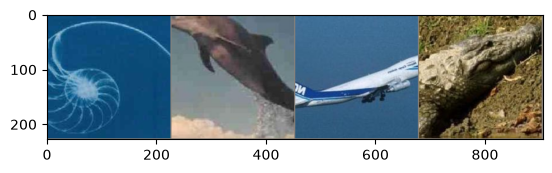

In [82]:
# visualizing images class

import matplotlib.pyplot as plt
import numpy as np

def imshow(img):
    img = unnormalize(img)
    np_img = img.numpy()
    plt.imshow(np.transpose(np_img, (1,2,0)))

# get some random training images
dataIter = iter(train_loader)
images, labels = next(dataIter)

imshow(torchvision.utils.make_grid(images[:4], nrow=4))
print([labels[j].item() for j in range(4)])

In [83]:
import torch.nn.functional as F

class Model(nn.Module):

    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)

        self.conv1 = nn.Conv2d(3, 32, 3)
        self.bn1 = nn.BatchNorm2d(32)

        self.conv2 = nn.Conv2d(32, 64, 3)
        self.bn2 = nn.BatchNorm2d(64)

        self.conv3 = nn.Conv2d(64, 128, 3)
        self.bn3 = nn.BatchNorm2d(128)

        self.fc1 = nn.Linear(128, 256)
        self.bn_fc1 = nn.BatchNorm1d(256)

        self.fc2 = nn.Linear(256, 128)
        self.bn_fc2 = nn.BatchNorm1d(128)

        self.fc3 = nn.Linear(128, 101)

        self.pool = nn.MaxPool2d(2, 2)
        self.global_avg_pool = nn.AdaptiveAvgPool2d(1)
        self.dropout = nn.Dropout(0.2)

    def forward(self, x):

        # x starts as (Batch, 3, 224, 224)
        x = self.pool(F.relu(self.bn1(self.conv1(x))))
        x = self.pool(F.relu(self.bn2(self.conv2(x))))
        x = self.pool(F.relu(self.bn3(self.conv3(x))))

        # Output shape: (Batch, 128, 1, 1)
        x = self.global_avg_pool(x)

        # Flatten the 1x1 spatial dims so it becomes a 2D tensor: (Batch, 128)
        x = torch.flatten(x, 1, -1)

        x = self.dropout(F.relu(self.bn_fc1(self.fc1(x))))
        x = self.dropout(F.relu(self.bn_fc2(self.fc2(x))))
        x = self.fc3(x)

        return x


In [84]:
device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else 'cpu'
print(device)

cuda


In [85]:
model = Model().to(device)

In [86]:
from torchinfo import summary

summary(model, input_size=(8, 3, 224, 224))

Layer (type:depth-idx)                   Output Shape              Param #
Model                                    [8, 101]                  --
├─Conv2d: 1-1                            [8, 32, 222, 222]         896
├─BatchNorm2d: 1-2                       [8, 32, 222, 222]         64
├─MaxPool2d: 1-3                         [8, 32, 111, 111]         --
├─Conv2d: 1-4                            [8, 64, 109, 109]         18,496
├─BatchNorm2d: 1-5                       [8, 64, 109, 109]         128
├─MaxPool2d: 1-6                         [8, 64, 54, 54]           --
├─Conv2d: 1-7                            [8, 128, 52, 52]          73,856
├─BatchNorm2d: 1-8                       [8, 128, 52, 52]          256
├─MaxPool2d: 1-9                         [8, 128, 26, 26]          --
├─AdaptiveAvgPool2d: 1-10                [8, 128, 1, 1]            --
├─Linear: 1-11                           [8, 256]                  33,024
├─BatchNorm1d: 1-12                      [8, 256]                  512

In [87]:
criterion = nn.CrossEntropyLoss()
optimizer =torch.optim.Adam(model.parameters(), lr = 0.01)

In [88]:
def train_one_epoch(epoch_index):
    running_loss = 0.

    # Here, we use enumerate(training_loader) instead of
    # iter(training_loader) so that we can track the batch
    # index and do some intra-epoch reporting
    for inputs, labels in (train_loader):
        # Every data instance is an input + label pair
        inputs, labels = inputs.to(device), labels.to(device)

        # Zero your gradients for every batch!
        optimizer.zero_grad()

        # Make predictions for this batch
        outputs = model(inputs)

        # Compute the loss and its gradients
        loss = criterion(outputs, labels)
        loss.backward()

        # Adjust learning weights
        optimizer.step()

        # Gather data and report
        running_loss += loss.item()

    return running_loss/len(train_loader)

In [89]:
def eval_one_epoch(index):

    running_vloss = 0.0
    
    # Disable gradient computation and reduce memory consumption.
    with torch.no_grad():
        for vinputs, vlabels in (test_loader):
            vinputs, vlabels = vinputs.to(device), vlabels.to(device)
            voutputs = model(vinputs)
            vloss = criterion(voutputs, vlabels)
            running_vloss += vloss.item()

    return running_vloss / (len(test_loader))

In [90]:
EPOCHS = 20
epoch_number = 0

for epoch in range(EPOCHS):
    print(f'EPOCH {epoch_number + 1}:')

    # Make sure gradient tracking is on, and do a pass over the data
    model.train(True)
    avg_loss = train_one_epoch(epoch_number)

    
    # Set the model to evaluation mode, disabling dropout and using population
    # statistics for batch normalization.
    model.eval()
    avg_vloss = eval_one_epoch(epoch_number)

    epoch_number +=1
    print(f'LOSS train {avg_loss} valid {avg_vloss}')

EPOCH 1:
LOSS train 4.083800661399068 valid 3.7147806888351793
EPOCH 2:
LOSS train 3.6899236534048336 valid 3.4025855498379824
EPOCH 3:
LOSS train 3.471449538996692 valid 3.1730350041719078
EPOCH 4:
LOSS train 3.3529168153138755 valid 3.001179201811689
EPOCH 5:
LOSS train 3.2214565373236135 valid 2.957256732448455
EPOCH 6:
LOSS train 3.1031622092844704 valid 2.8137935844983923
EPOCH 7:
LOSS train 2.9794018371588624 valid 2.6936129328841987
EPOCH 8:
LOSS train 2.8898718700430908 valid 2.6761514794441963
EPOCH 9:
LOSS train 2.8032223880290985 valid 2.528645192972526
EPOCH 10:
LOSS train 2.7462758411597545 valid 2.525636713625649
EPOCH 11:
LOSS train 2.6823524619851793 valid 2.397499084747332
EPOCH 12:
LOSS train 2.679898902773857 valid 2.4609158335742864
EPOCH 13:
LOSS train 2.631023558534785 valid 2.495025488363433
EPOCH 14:
LOSS train 2.605055524044872 valid 2.3644277288617075
EPOCH 15:
LOSS train 2.551406550379942 valid 2.400849985362198
EPOCH 16:
LOSS train 2.5432515636704482 valid 2

In [91]:
import torch

def evaluate_multiclass_accuracy(model, test_loader):
    # Set model to evaluation mode (turns off dropout and fixes batchnorm layers)
    model.eval()
    
    total_correct = 0
    total_samples = 0
    
    # Disable gradient tracking to save memory and speed up computation
    with torch.no_grad():
        for inputs, targets in test_loader:
            # Move data to the active device (CPU or GPU)
            inputs, targets = inputs.to(device), targets.to(device)
            
            # Forward pass to get raw logits: shape (batch_size, num_classes)
            logits = model(inputs)
            
            # 1. Get the predicted class indices along the class dimension (dim=1)
            preds = torch.argmax(logits, dim=1)
            
            # 2. Compare predictions to ground truth labels and sum the correct matches
            correct_batch = (preds == targets).sum().item()
            
            # 3. Accumulate total correct predictions and total samples seen
            total_correct += correct_batch
            total_samples += targets.size(0)
            
    # Calculate final accuracy across the entire test dataset
    final_accuracy = total_correct / total_samples
    return final_accuracy

# --- Example Usage ---

test_acc = evaluate_multiclass_accuracy(model, train_loader)
print(f"Test Accuracy: {test_acc * 100:.2f}%")


Test Accuracy: 50.45%
